# Задача 2. Изотропный источник света

Создать класс `Source` со световым выходом $Y=10\,000$ фотонов/МэВ
и методом генерации начальных направлений для события с энергией $E$.
Реализация находится в [source.py](source.py).

Выход линеен: $M=\operatorname{round}(YE)$. Число фотонов при данной энергии
фиксировано; флуктуации светового выхода в условии не заданы.

Для изотропии разыгрываем независимые величины
$u=\cos\theta\sim U[-1,1]$ и $\varphi\sim U[0,2\pi)$, после чего
$$\mathbf n=(\sqrt{1-u^2}\cos\varphi,\sqrt{1-u^2}\sin\varphi,u).$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from source import Source
%matplotlib inline

source = Source(Y=10000, seed=42)
directions = source.sample_directions(E=1.0)
print('Число фотонов и форма массива:', directions.shape)
print('Первые пять направлений:')
print(np.round(directions[:5], 6))
print('Среднее направление:', directions.mean(axis=0))
print('Средние квадраты компонент:', np.mean(directions**2, axis=0))
print('Максимальное отклонение длины от 1:',
      np.max(np.abs(np.linalg.norm(directions, axis=1)-1)))
assert directions.shape == (10000, 3)
np.testing.assert_allclose(np.linalg.norm(directions, axis=1), 1, atol=1e-14)
assert source.sample_directions(0).shape == (0, 3)

Число фотонов и форма массива: (10000, 3)
Первые пять направлений:
[[-0.152989 -0.822427  0.547912]
 [-0.239341 -0.963209 -0.122243]
 [ 0.204092  0.666316  0.717196]
 [ 0.894534  0.209744  0.394736]
 [-0.193723  0.551093 -0.811645]]
Среднее направление: [ 0.0049936  -0.00505856 -0.0057568 ]
Средние квадраты компонент: [0.33085623 0.33685866 0.33228511]
Максимальное отклонение длины от 1: 2.220446049250313e-16


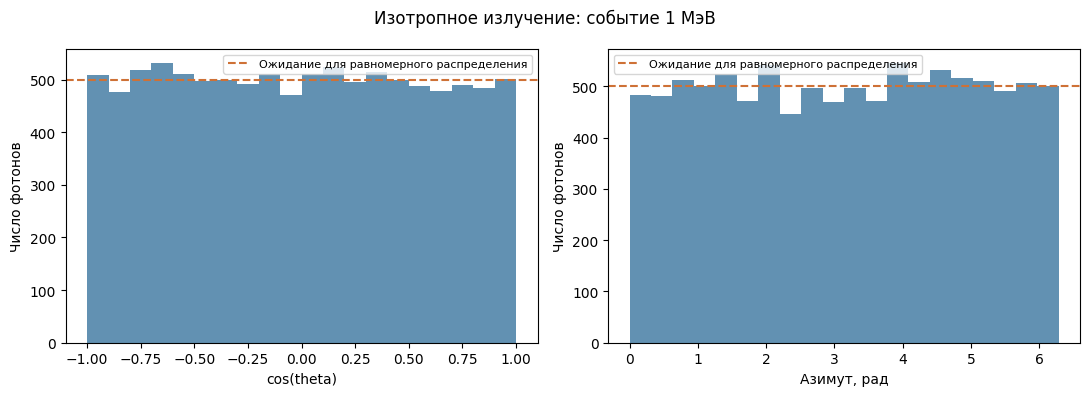

In [2]:
cos_theta = directions[:, 2]
phi = np.mod(np.arctan2(directions[:, 1], directions[:, 0]), 2*np.pi)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, values, limits, label in (
    (axes[0], cos_theta, (-1, 1), 'cos(theta)'),
    (axes[1], phi, (0, 2*np.pi), 'Азимут, рад'),
):
    ax.hist(values, bins=20, range=limits, color='#2E6C98', alpha=0.75)
    ax.axhline(len(directions)/20, color='#CE7136', linestyle='--',
               label='Ожидание для равномерного распределения')
    ax.set(xlabel=label, ylabel='Число фотонов')
    ax.legend(fontsize=8)
fig.suptitle('Изотропное излучение: событие 1 МэВ')
fig.tight_layout()
Path('figures').mkdir(exist_ok=True)
fig.savefig('figures/source_isotropy.png', dpi=150, bbox_inches='tight')
plt.show()

Длины направлений равны единице. Для изотропного распределения ожидается
$\langle n_i\rangle=0$ и $\langle n_i^2\rangle=1/3$.
Гистограммы $\cos\theta$ и азимута согласуются с равномерным распределением.